# M2 IA agéntica - Generación de gráficos

¡Nos alegra tenerte aquí en el curso de **IA Agéntica**! En este **laboratorio no evaluado**, y en los que seguirán durante el resto del curso, tendrás la oportunidad de probar ejemplos de código que implementan los conceptos y patrones de diseño que verás en los vídeos de las clases.

Piensa en estos laboratorios como un **entorno de pruebas**: un espacio seguro para practicar donde puedes profundizar en tu comprensión de los conceptos del curso, ganar confianza y prepararte para los ejercicios evaluados que vendrán después. En cada laboratorio, intenta ejecutar las celdas de código para ver algunos flujos de trabajo agénticos en acción y comprender mejor cómo funcionan.

En algunos puntos, se te animará a realizar modificaciones en el código, como cambiar los prompts, probar con distintos LLM o añadir consultas adicionales al flujo de trabajo. Experimenta para observar cómo tus cambios afectan al comportamiento del flujo de trabajo.

Lo más importante es que los laboratorios no evaluados son una oportunidad para aprender a tu propio ritmo mientras adquieres experiencia práctica con las ideas fundamentales de la **IA Agéntica**. Y recuerda: ¡no estás aprendiendo solo! Si tienes alguna pregunta, no dudes en consultar a la
<a href="https://community.deeplearning.ai/c/course-q-a/agentic-ai/567" target="_blank">comunidad</a>


## 1. Introducción
### 1.1. Descripción general del laboratorio

En este laboratorio no evaluado, implementarás el **patrón de reflexión** presentado en el vídeo de la clase dentro de un flujo de trabajo agéntico que genera visualizaciones de datos. Un LLM multimodal revisará el primer borrador del gráfico, identificará posibles mejoras, como el tipo de gráfico, las etiquetas o los colores, y después reescribirá el código de generación del gráfico para producir una visualización más eficaz.

En el vídeo, Andrew presentó el siguiente flujo de trabajo para analizar las ventas de café. Aquí lo implementarás mediante código. Estos son los pasos que realizará el flujo de trabajo:

1. **Generar una versión inicial (V1):**
Usar un Large Language Model (LLM) para crear la primera versión del código de representación gráfica.

2. **Ejecutar el código y crear el gráfico:** 
Ejecutar el código generado y mostrar el gráfico resultante.

3. **Reflexionar sobre el resultado:**
Evaluar tanto el código como el gráfico mediante un LLM para detectar áreas de mejora, por ejemplo, claridad, precisión y diseño.

4. **Generar y ejecutar una versión mejorada (V2):**
Producir una versión refinada del código de representación gráfica basándose en las conclusiones de la reflexión y mostrar el gráfico mejorado.

<img src='M2-UGL-2.png'>

### 🎯 1.2. Resultado de aprendizaje

Al finalizar este laboratorio, habrás implementado el patrón de reflexión en código y lo habrás utilizado para mejorar una visualización de datos.

## 2. Configuración: Inicializar el entorno y el cliente

En este paso, importas las bibliotecas principales que darán soporte al flujo de trabajo:

- **`re`**: módulo de expresiones regulares de Python, que utilizarás para extraer fragmentos de código o texto estructurado de la salida del LLM.
- **`json`**: proporciona funciones para leer y escribir JSON, útil para gestionar las respuestas estructuradas devueltas por el LLM.
- **`utils`**: módulo auxiliar personalizado proporcionado para este laboratorio. Incluye utilidades para trabajar con el conjunto de datos, generar gráficos y mostrar los resultados de forma limpia y legible.


In [9]:
# Importaciones de la biblioteca estándar
import re
import json

# Módulo auxiliar local
import utils


### 2.1. Carga del conjunto de datos

Vamos a echar un vistazo a los datos de ventas de café para ver qué información contiene el archivo.

In [10]:
# Utiliza esta función de utils.py para cargar los datos en un dataframe
df = utils.load_and_prepare_data('coffee_sales.csv')

# Obtén una muestra aleatoria para mostrarla
utils.print_html(df.sample(n=5), title="Random Sample of Coffee Sales Data")

date,time,cash_type,card,price,coffee_name,quarter,month,year
2025-03-13,15:12,card,ANON-0000-0000-1285,3.086,Americano with Milk,1,3,2025
2025-01-25,06:31,card,ANON-0000-0000-1114,3.576,Cappuccino,1,1,2025
2024-11-12,12:47,card,ANON-0000-0000-0891,3.576,Cocoa,4,11,2024
2024-11-17,11:52,card,ANON-0000-0000-0917,3.086,Americano with Milk,4,11,2024
2024-04-01,12:35,card,ANON-0000-0000-0009,3.380,Americano with Milk,2,4,2024


Construirás un flujo de trabajo agéntico que genera visualizaciones de datos a partir de este conjunto de datos, ayudándote a responder preguntas sobre las ventas de café de la máquina expendedora.

## 3. Construcción del flujo de trabajo

### 3.1 Paso 1 — Generar código para crear un gráfico (V1)

En este paso, pedirás a un LLM que escriba código Python para generar un gráfico en respuesta a una consulta de usuario sobre el conjunto de datos de café. El conjunto de datos incluye los campos `date`, `time`, `cash_type`, `card`, `price` y `coffee_name` (además de `year`, `quarter` y `month`, derivados de `date` cuando se carga el conjunto de datos), y pasarás este esquema al LLM para que sepa qué datos están disponibles.

La pregunta que harás al modelo es la misma que se utilizó en la clase:
**“Crea un gráfico que compare las ventas de café del primer trimestre de 2024 y 2025 utilizando los datos de coffee_sales.csv.”**

La salida del LLM será código Python que utiliza la biblioteca **matplotlib**. En lugar de mostrar directamente el gráfico, el código se escribirá entre etiquetas `<execute_python>` para que pueda extraerse y ejecutarse en pasos posteriores. Aprenderás más sobre estas etiquetas en el Módulo 3.

In [11]:
def generate_chart_code(instruction: str, model: str, out_path_v1: str) -> str:
    """Generate Python code to make a plot with matplotlib using tag-based wrapping."""

    prompt = f"""
    You are a data visualization expert.

    Return your answer *strictly* in this format:

    <execute_python>
    # valid python code here
    </execute_python>

    Do not add explanations, only the tags and the code.

    The code should create a visualization from a DataFrame 'df' with these columns:
    - date   (datetime64 — already parsed; use df['date'].dt.year, df['date'].dt.month, etc.)
    - time   (string, HH:MM — do NOT concatenate or combine with the date column)
    - cash_type (string: 'card' or 'cash')
    - card (string)
    - price (number)
    - coffee_name (string)
    - quarter (int, 1–4 — already computed, use directly)
    - month  (int, 1–12 — already computed, use directly)
    - year   (int, e.g. 2024 — already computed, use directly)

    User instruction: {instruction}

    Requirements for the code:
    1. Assume the DataFrame is already loaded as 'df'.
    2. Use matplotlib for plotting.
    3. Add clear title, axis labels, and legend if needed.
    4. Save the figure as '{out_path_v1}' with dpi=300.
    5. Do not call plt.show().
    6. Close all plots with plt.close().
    7. Add all necessary import python statements
    8. CRITICAL: 'date' is datetime64 — never use string concatenation on it.
       Filter by year/quarter using the 'year' and 'quarter' integer columns.
    9. CRITICAL: when aggregating (sum, mean, count, etc.), always select the numeric
       column explicitly, e.g. df.groupby(['year', 'coffee_name'])['price'].sum().
       Never call .sum() or .mean() on the whole DataFrame or on a groupby without
       selecting a column — non-numeric columns like 'date' will raise a TypeError.
    
    Return ONLY the code wrapped in <execute_python> tags.
    """

    response = utils.get_response(model, prompt)
    return response

Ahora, ¡prueba la función y analiza la respuesta!

In [12]:
# Generar el código inicial
code_v1 = generate_chart_code(
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv.", 
    model="gpt-4o-mini", 
    out_path_v1="chart_v1.png"
)

utils.print_html(code_v1, title="LLM output with first draft code")

¡Genial! Has generado código Python para crear un gráfico.

Observa que el código está encerrado entre las etiquetas `<execute_python>`. Estas etiquetas facilitan la extracción y ejecución automática del código en el siguiente paso del flujo de trabajo.

No necesitas preocuparte todavía por los detalles; aprenderás más sobre cómo funcionan estas etiquetas en el **Módulo 3**.

### 3.2. Paso 2 — Ejecutar el código y crear el gráfico

En este paso, utilizarás una expresión regular para extraer el código Python que el LLM generó en el paso anterior (la parte escrita entre las etiquetas `<execute_python>`). Una vez extraído, ejecutarás este código para producir el **primer borrador del gráfico**.

Así es como funciona:

1. **Extraer el código:**
   Se utiliza un patrón regex para obtener el código que está encerrado dentro de las etiquetas `<execute_python>`.

2. **Ejecutar el código:**
   El código extraído se ejecuta en un contexto global predefinido donde el DataFrame `df` ya está disponible. Esto significa que tu código puede utilizar directamente `df` sin necesidad de volver a cargar el conjunto de datos.

3. **Generar el gráfico:**
   Si el código se ejecuta correctamente, creará un gráfico y lo guardará como `chart_v1.png`.

4. **Ver el gráfico en el notebook:**
   El gráfico guardado se muestra en línea mediante `utils.print_html`, lo que facilita la revisión de los resultados.

Al completar este paso, tendrás lista tu primera visualización de borrador (V1), un hito importante en el flujo de trabajo de reflexión.


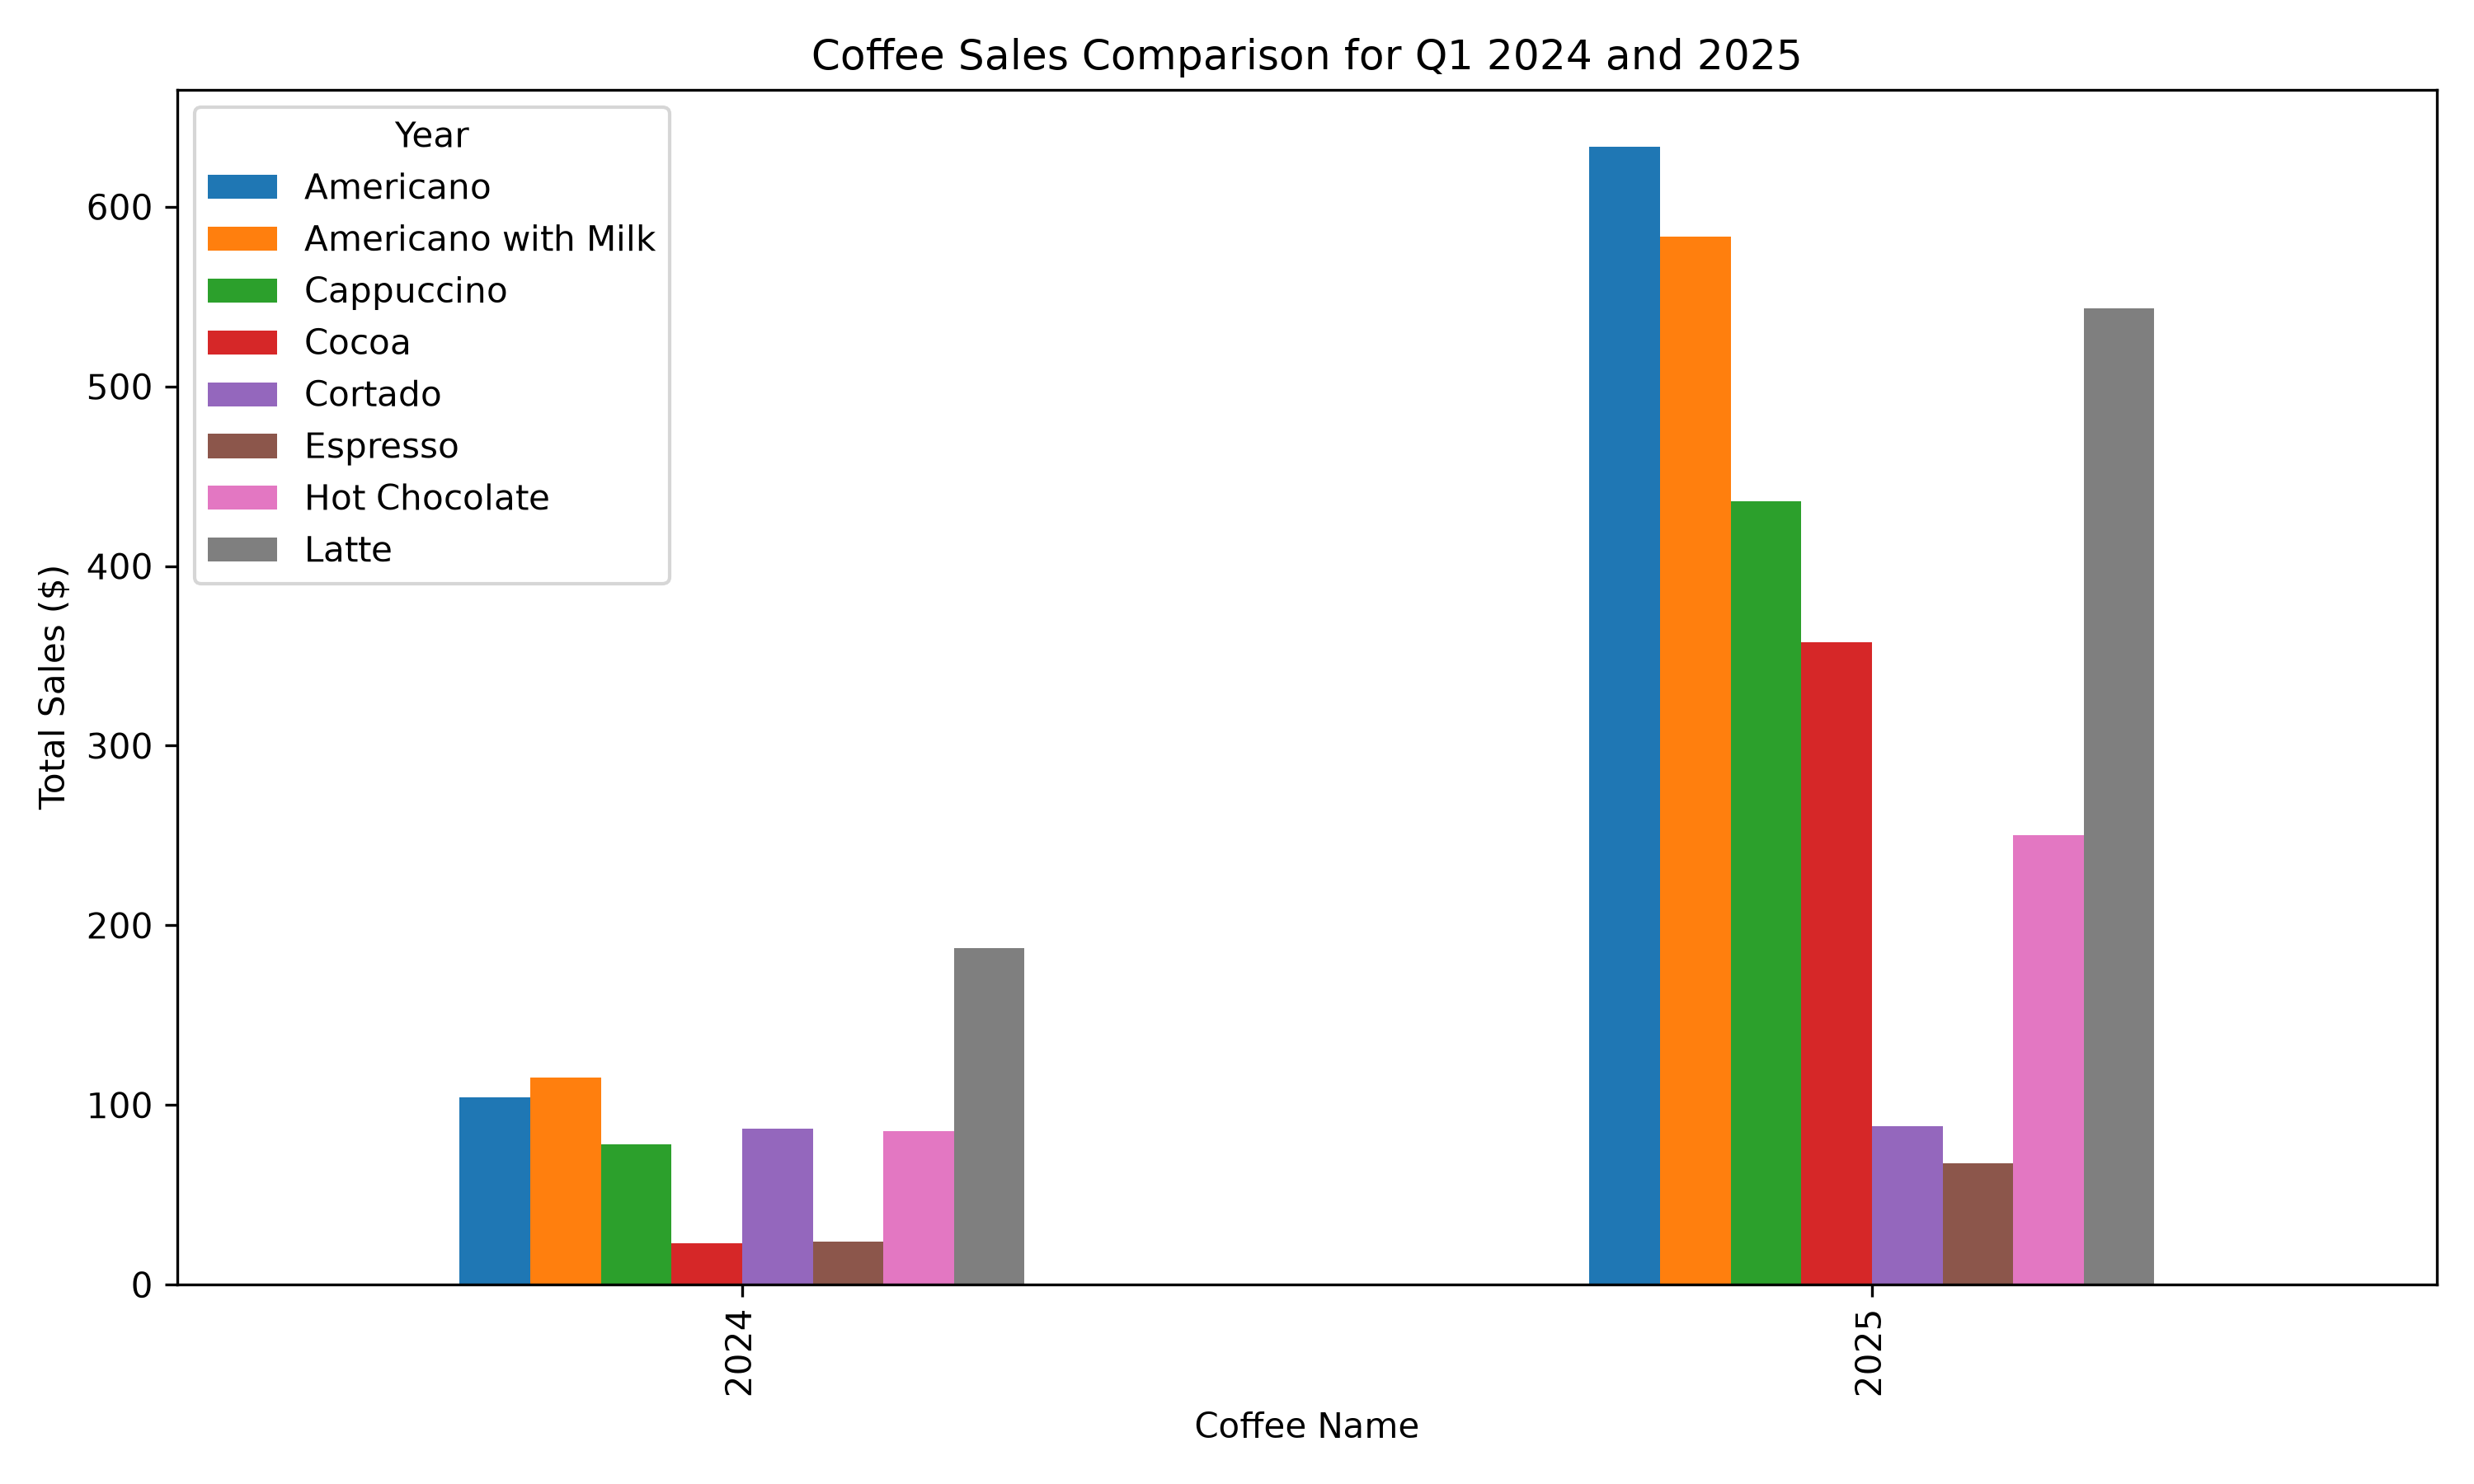

In [13]:
# Obtener el código dentro de las etiquetas <execute_python>
match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
if match:
    initial_code = match.group(1).strip()
    utils.print_html(initial_code, title="Extracted Code to Execute")
    exec_globals = {"df": df}
    exec(initial_code, exec_globals)

# Si el código se ejecuta correctamente, debería haberse generado el archivo chart_v1.png
utils.print_html(
    content="chart_v1.png",
    title="Generated Chart (V1)",
    is_image=True
)

### 3.3. Paso 3 — Reflexionar sobre el resultado

El objetivo aquí es simular cómo una persona revisaría el primer borrador de un gráfico: buscando fortalezas, debilidades y áreas de mejora.

Esto es lo que ocurre:

**1. Proporcionar el gráfico al LLM:**
El gráfico generado (`chart_v1.png`) se comparte con el LLM para que pueda “ver” la visualización.

**2. Analizar visualmente el gráfico:**
El LLM revisa elementos como la claridad, el etiquetado, la precisión y la legibilidad general.

**3. Generar comentarios:**
El LLM sugiere mejoras, por ejemplo, corregir las etiquetas de los ejes, ajustar el tipo de gráfico, mejorar la elección de colores o destacar leyendas ausentes.

De este modo, creas un ciclo de retroalimentación inteligente en el que el gráfico no se produce simplemente una vez, sino que se somete activamente a una crítica, preparando el terreno para una segunda versión más sólida (V2).

In [14]:
def reflect_on_image_and_regenerate(
    chart_path: str,
    instruction: str,
    model_name: str,
    out_path_v2: str,
    code_v1: str,  
) -> tuple[str, str]:
    """
    Critique the chart IMAGE and the original code against the instruction, 
    then return refined matplotlib code.
    Returns (feedback, refined_code_with_tags).
    Works with OpenAI vision-capable models (e.g. gpt-4o-mini, gpt-4o, gpt-4.1, o4-mini).
    """
    media_type, b64 = utils.encode_image_b64(chart_path)
    

    prompt = f"""
    You are a data visualization expert.
    Your task: critique the attached chart and the original code against the given instruction,
    then return improved matplotlib code.

    Original code (for context):
    {code_v1}

    OUTPUT FORMAT (STRICT):
    1) First line: a valid JSON object with ONLY the "feedback" field.
    Example: {{"feedback": "The legend is unclear and the axis labels overlap."}}

    2) After a newline, output ONLY the refined Python code wrapped in:
    <execute_python>
    ...
    </execute_python>

    3) Import all necessary libraries in the code. Don't assume any imports from the original code.

    HARD CONSTRAINTS:
    - Do NOT include Markdown, backticks, or any extra prose outside the two parts above.
    - Use pandas/matplotlib only (no seaborn).
    - Assume df already exists; do not read from files.
    - Save to '{out_path_v2}' with dpi=300.
    - Always call plt.close() at the end (no plt.show()).
    - Include all necessary import statements.
    
    IMPORTANT: The 'date' column is already a pandas datetime64 type.
    - Do NOT concatenate 'date' with 'time' using string operations.
    - To filter by year/quarter, use: df[df['year'] == 2024] or df['date'].dt.year == 2024
    - The 'quarter' and 'year' columns already exist as integers; use them directly.

    Schema (columns available in df):
    - date   (datetime64 — already parsed; use df['date'].dt.year, etc.)
    - time   (string, HH:MM — do NOT concatenate with date)
    - cash_type (string: 'card' or 'cash')
    - card   (string)
    - price  (float)
    - coffee_name (string)
    - quarter (int, 1–4)
    - month  (int, 1–12)
    - year   (int)
    
    CRITICAL TYPE RULE: 'date' is already datetime64.
    - NEVER do: df['date'] + ' ' + df['time']  ← this will crash
    - ALWAYS filter by year/quarter using the integer columns: df[df['year'] == 2024]

    Instruction:
    {instruction}
    """


    # Enviar la imagen del gráfico + el prompt al modelo de reflexión
    content = utils.image_openai_call(model_name, prompt, media_type, b64)

    # --- Analizar SOLO la primera línea JSON (comentarios) ---
    lines = content.strip().splitlines()
    json_line = lines[0].strip() if lines else ""

    try:
        obj = json.loads(json_line)
    except Exception as e:
        # Alternativa: intentar capturar el primer {...} de todo el contenido
        m_json = re.search(r"\{.*?\}", content, flags=re.DOTALL)
        if m_json:
            try:
                obj = json.loads(m_json.group(0))
            except Exception as e2:
                obj = {"feedback": f"Failed to parse JSON: {e2}", "refined_code": ""}
        else:
            obj = {"feedback": f"Failed to find JSON: {e}", "refined_code": ""}

    # --- Extraer el código refinado de <execute_python>...</execute_python> ---
    m_code = re.search(r"<execute_python>([\s\S]*?)</execute_python>", content)
    refined_code_body = m_code.group(1).strip() if m_code else ""
    refined_code = utils.ensure_execute_python_tags(refined_code_body)

    feedback = str(obj.get("feedback", "")).strip()
    return feedback, refined_code



Observa que el modelo recibe instrucciones para devolver su respuesta en **formato JSON**.

- JSON es un formato ligero y estructurado (pares clave-valor) que facilita el análisis programático de la salida del LLM.
- Aquí exigimos dos campos:
  - **`feedback`**: una breve crítica del gráfico actual.
  - **`refined_code`**: un fragmento de código Python mejorado, encerrado en etiquetas `<execute_python>`.

También incluimos una sección de **“constraints”** en el prompt. Estas reglas, como usar únicamente matplotlib, guardar el archivo en una ruta específica o llamar a `plt.close()` al final, ayudan al modelo a generar código coherente y ejecutable que encaje con el flujo de trabajo. Sin estas restricciones, la salida podría variar demasiado o incluir un formato no deseado.

### 3.4 Paso 4 — Generar y ejecutar la versión mejorada (V2)

En este paso final, es el momento de generar y ejecutar la versión mejorada del gráfico (V2).
Después de ejecutar la celda, verás **tanto la reflexión escrita por el LLM** (que explica qué necesitaba mejorar) **como el nuevo código que ha generado**. A continuación, el nuevo código se ejecutará para producir el gráfico actualizado.

In [15]:
# Generar comentarios junto con el código reflejado
feedback, code_v2 = reflect_on_image_and_regenerate(
    chart_path="chart_v1.png",            
    instruction="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv.", 
    model_name="o4-mini",
    out_path_v2="chart_v2.png",
    code_v1=code_v1,   # pasar el código original como contexto        
)

utils.print_html(feedback, title="Feedback on V1 Chart")
utils.print_html(code_v2, title="Regenerated Code Output (V2)")

Ahora ejecutarás el código refinado devuelto por el paso de reflexión. El código dentro de las etiquetas `<execute_python>` se extrae, se ejecuta sobre el conjunto de datos y se utiliza para generar el gráfico actualizado.

Si la ejecución tiene éxito, verás la nueva imagen (`chart_v2.png`) mostrada a continuación como el **Gráfico regenerado (V2)**.


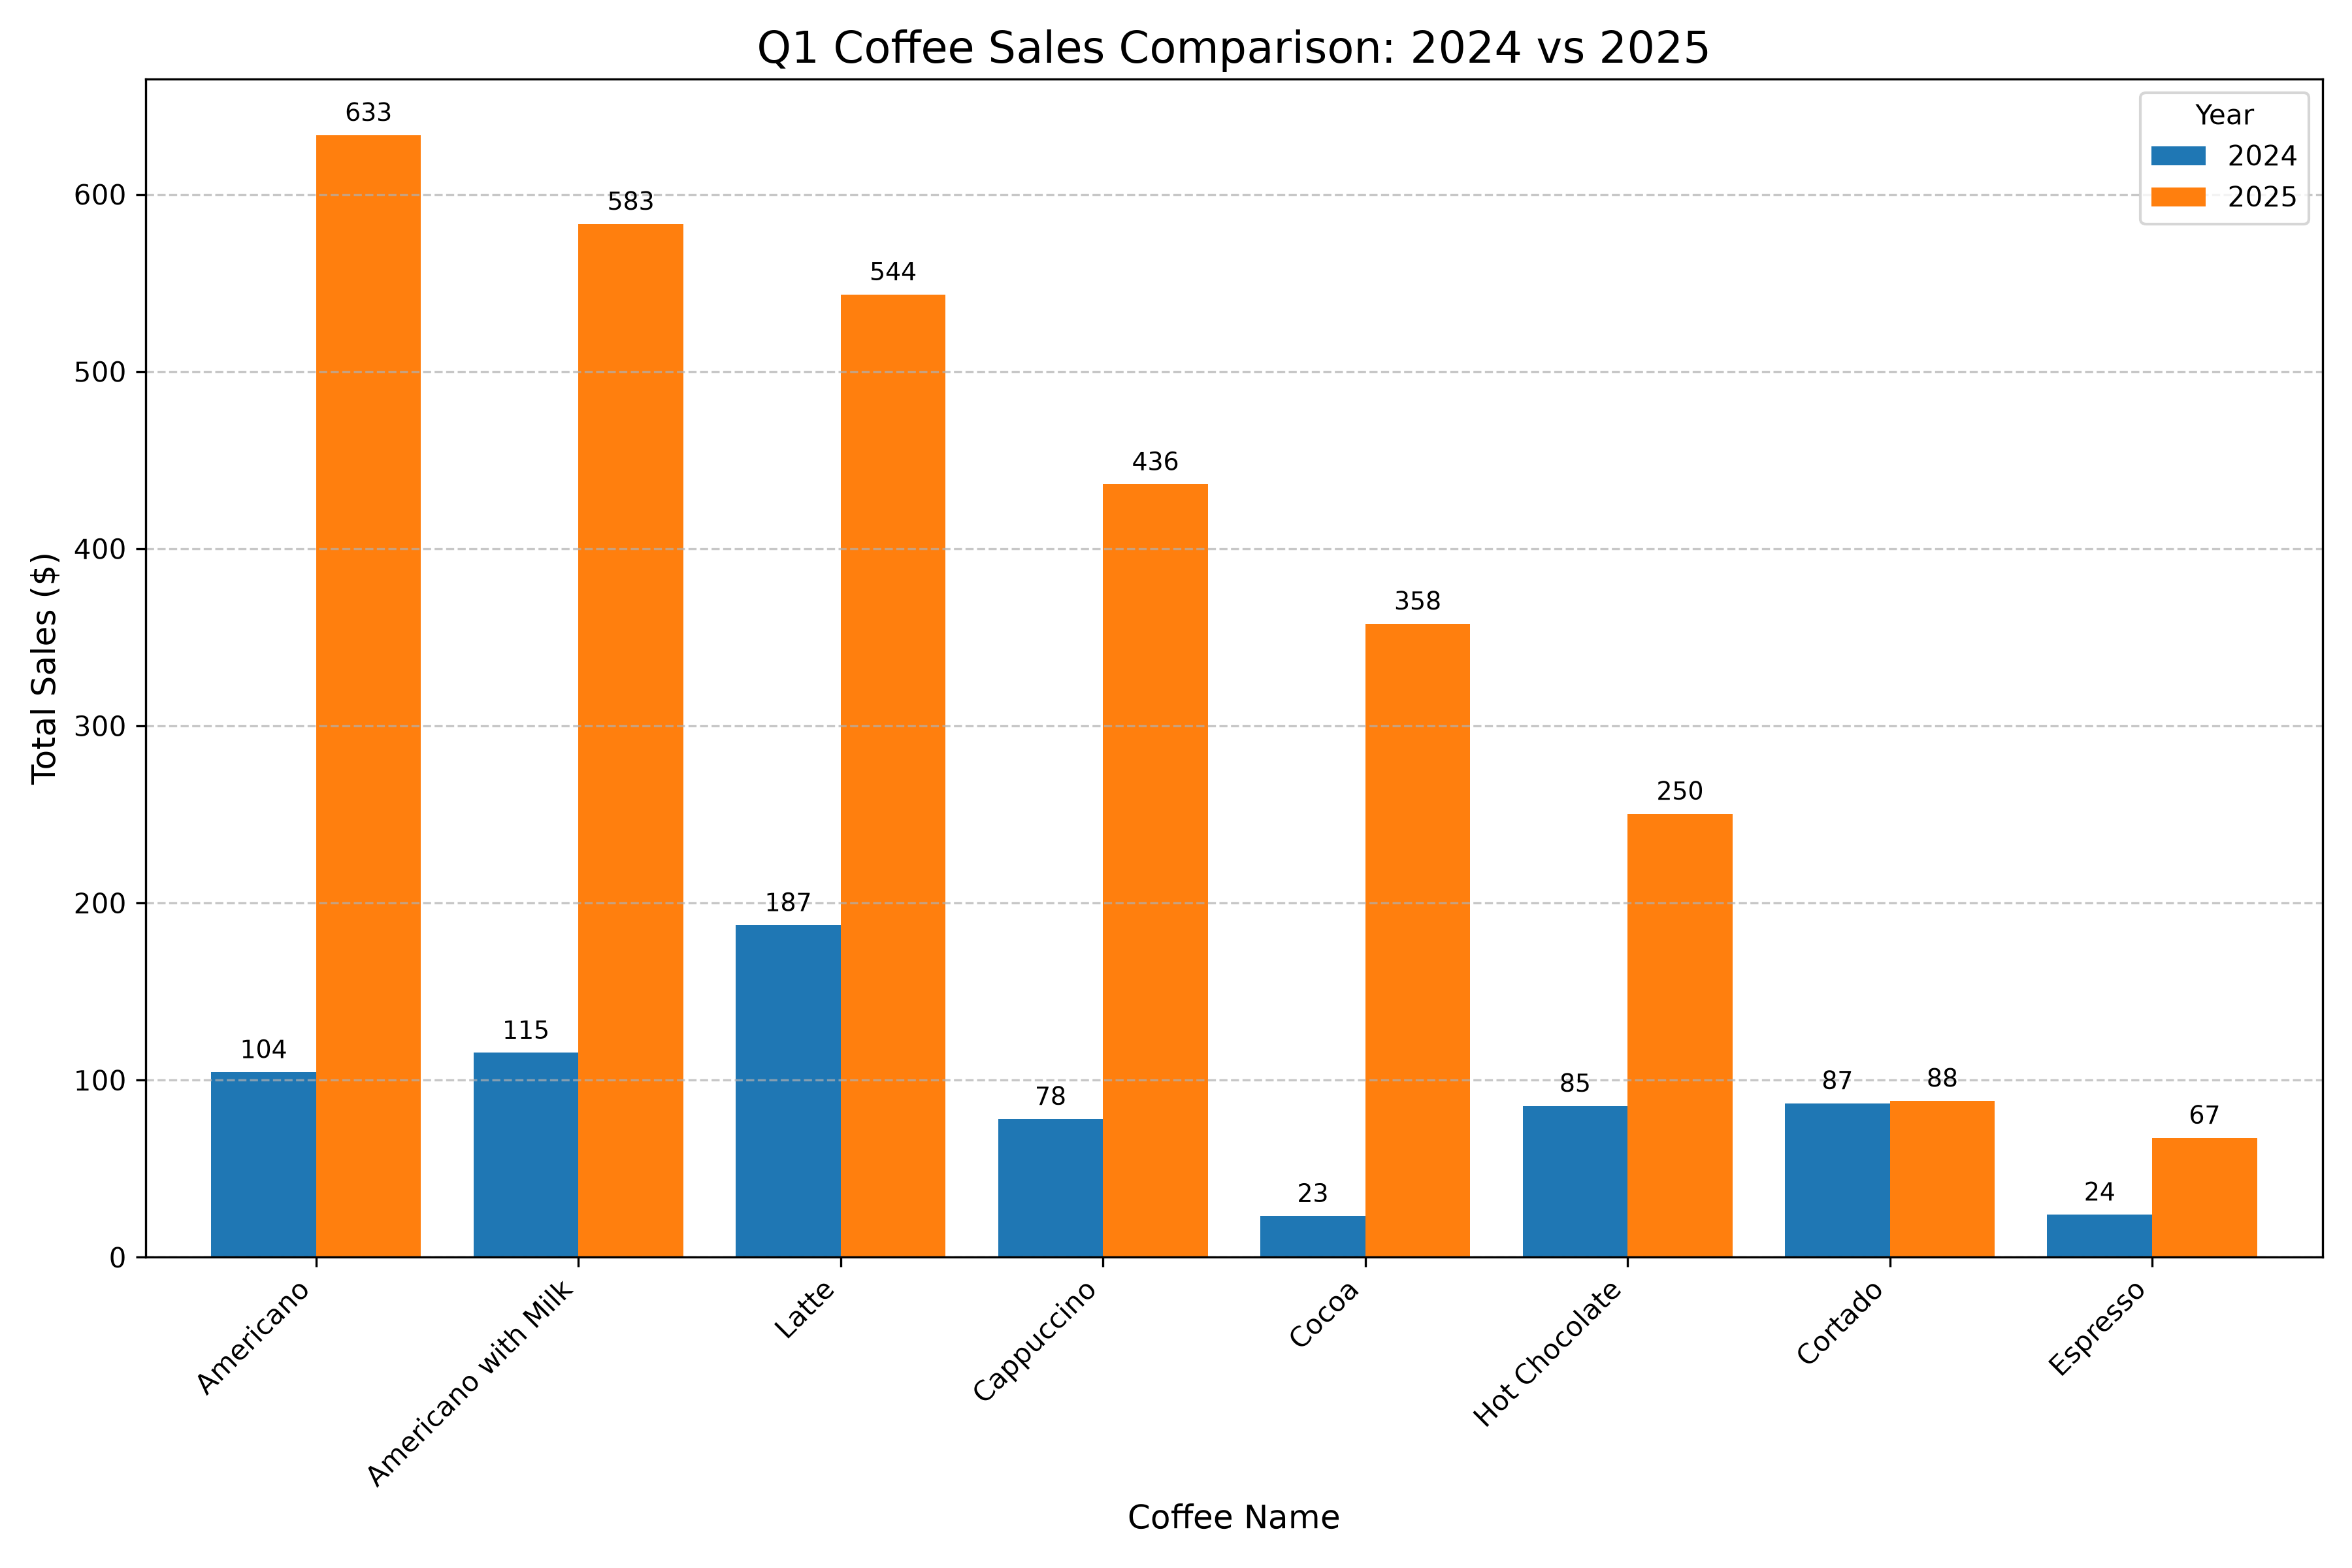

In [16]:
# Obtener el código dentro de las etiquetas <execute_python>
match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2)
if match:
    reflected_code = match.group(1).strip()
    exec_globals = {"df": df}
    exec(reflected_code, exec_globals)

# Si el código se ejecuta correctamente, debería haberse generado el archivo chart_v2.png
utils.print_html(
    content="chart_v2.png",
    title="Regenerated Chart (V2)",
    is_image=True
)

### 4. Unirlo todo — crear el flujo de trabajo de extremo a extremo

Ahora es el momento de integrar todo en un único flujo de trabajo automatizado que el agente pueda ejecutar de principio a fin.

La función `run_workflow` conecta los componentes que implementaste anteriormente:

1) **Cargar y preparar los datos** — mediante `utils.load_and_prepare_data(...)`.
2) **Generar el código V1** — con `generate_chart_code(...)`, que devuelve el código matplotlib del primer borrador (encerrado en etiquetas `<execute_python>`).
3) **Ejecutar V1 inmediatamente** — el flujo extrae el código situado entre las etiquetas `<execute_python>` y lo ejecuta para producir la primera imagen del gráfico.
4) **Reflexionar y refinar** — `reflect_on_image_and_regenerate(...)` critica la imagen V1 (y el código original) según la instrucción y devuelve **comentarios** breves además del **código revisado (V2)**.
5) **Ejecutar V2 inmediatamente** — se extrae y ejecuta el código refinado para generar el gráfico mejorado.

### Qué acepta este flujo de trabajo
- **`dataset_path`**: ubicación del CSV de entrada.
- **`user_instructions`**: la petición para el gráfico (por ejemplo, “Crea un gráfico que compare las ventas de café del primer trimestre de 2024 y 2025 utilizando los datos de coffee_sales.csv.”).
- **`generation_model`**: modelo utilizado para la generación inicial del código.
- **`reflection_model`**: modelo utilizado para la reflexión basada en la imagen y el refinamiento del código.
- **`image_basename`**: nombre base de archivo para guardar las imágenes de los gráficos (por ejemplo, `chart_v1.png`, `chart_v2.png`).

> Nota: Los pasos de ejecución del gráfico están deliberadamente **codificados de forma fija** para ejecutarse justo después de la generación/refinamiento del código. Esto refleja el flujo de trabajo mostrado en la clase y garantiza que puedas ver el resultado de cada borrador antes de continuar.

In [17]:
def run_workflow(
    dataset_path: str,
    user_instructions: str,
    generation_model: str,
    reflection_model: str,   
    image_basename: str = "chart",
):
    """
    End-to-end pipeline:
      1) load dataset
      2) generate V1 code
      3) execute V1 → produce chart_v1.png
      4) reflect on V1 (image + original code) → feedback + refined code
      5) execute V2 → produce chart_v2.png

    Returns a dict with all artifacts (codes, feedback, image paths).
    """
    # 0) Cargar el conjunto de datos; utils gestiona el análisis y la derivación de características (por ejemplo, año/trimestre)
    df = utils.load_and_prepare_data(dataset_path)
    utils.print_html(df.sample(n=5), title="Random Sample of Dataset")

    # Rutas para guardar los gráficos
    out_v1 = f"{image_basename}_v1.png"
    out_v2 = f"{image_basename}_v2.png"

    # 1) Generar código (V1)
    utils.print_html("Step 1: Generating chart code (V1)… 📈")
    code_v1 = generate_chart_code(
        instruction=user_instructions,
        model=generation_model,
        out_path_v1=out_v1,
    )
    utils.print_html(code_v1, title="LLM output with first draft code (V1)")

    # 2) Ejecutar V1 (codificado de forma fija: extraer el bloque <execute_python> y ejecutarlo inmediatamente)
    utils.print_html("Step 2: Executing chart code (V1)… 💻")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v1)
    if match:
        initial_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(initial_code, exec_globals)
    utils.print_html(out_v1, is_image=True, title="Generated Chart (V1)")

    # 3) Reflexionar sobre V1 (imagen + código original) para obtener comentarios y código refinado (V2)
    utils.print_html("Step 3: Reflecting on V1 (image + code) and generating improvements… 🔁")
    feedback, code_v2 = reflect_on_image_and_regenerate(
        chart_path=out_v1,
        instruction=user_instructions,
        model_name=reflection_model,
        out_path_v2=out_v2,
        code_v1=code_v1,  # pasar el código original como contexto
    )
    utils.print_html(feedback, title="Reflection feedback on V1")
    utils.print_html(code_v2, title="LLM output with revised code (V2)")

    # 4) Ejecutar V2 (codificado de forma fija: extraer el bloque <execute_python> y ejecutarlo inmediatamente)
    utils.print_html("Step 4: Executing refined chart code (V2)… 🖼️")
    match = re.search(r"<execute_python>([\s\S]*?)</execute_python>", code_v2)
    if match:
        reflected_code = match.group(1).strip()
        exec_globals = {"df": df}
        exec(reflected_code, exec_globals)
    utils.print_html(out_v2, is_image=True, title="Regenerated Chart (V2)")

    return {
        "code_v1": code_v1,
        "chart_v1": out_v1,
        "feedback": feedback,
        "code_v2": code_v2,
        "chart_v2": out_v2,
    }


### 4.2. Prueba el flujo de trabajo

Ahora es tu turno de poner en acción el flujo de trabajo completo con el ejemplo actualizado de la clase.

- **Instrucción que debes utilizar:**
  “Crea un gráfico que compare las ventas de café del primer trimestre de 2024 y 2025 utilizando los datos de coffee_sales.csv.”

Cuando ejecutes el flujo de trabajo con esta instrucción, hará lo siguiente:
1. Generará el código del primer borrador para crear el gráfico.
2. Ejecutará ese código inmediatamente para producir la primera versión del gráfico (V1).
3. Reflexionará sobre el gráfico y el código original, generando comentarios y un código revisado (V2).
4. Ejecutará el código refinado para generar el gráfico mejorado (V2).

### Personaliza y experimenta

Después de probar el ejemplo anterior, puedes actualizar el parámetro `user_instructions` con tus propias peticiones de gráficos.
Recuerda ajustar también `image_basename` para que cada ejecución guarde los resultados con un nombre de archivo nuevo; así mantendrás tus gráficos organizados y evitarás sobrescribir resultados anteriores.

### Elección de modelos

Puedes combinar distintos modelos para la generación y la reflexión. Por ejemplo:
- Utiliza un modelo rápido para la generación inicial del código (`gpt-4o-mini` o `gpt-4.1-mini`).
- Utiliza un modelo de razonamiento más potente para la reflexión (`gpt-4.1`, `gpt-4o` u `o4-mini`).

**Nota:** Los modelos disponibles en este laboratorio son `gpt-4o-mini`, `gpt-4o`, `gpt-4.1`, `gpt-4.1-mini` y `o4-mini`. Ten también en cuenta que el modelo de reflexión puede elegir razonablemente un tipo de gráfico diferente (por ejemplo, un gráfico de líneas en lugar de barras); esto forma parte del criterio del modelo y no es un error.

Esta flexibilidad te permite explorar las ventajas y desventajas entre velocidad y calidad.

👉 **Ahora es tu turno:** ejecuta el flujo de trabajo con la instrucción de ejemplo de la clase. Después, experimenta con tus propios prompts para observar cómo se adapta el agente.

date,time,cash_type,card,price,coffee_name,quarter,month,year
2024-12-29,17:39,card,ANON-0000-0000-0729,3.576,Latte,4,12,2024
2024-10-12,13:12,card,ANON-0000-0000-0507,3.576,Latte,4,10,2024
2025-03-09,13:57,card,ANON-0000-0000-1153,3.576,Cappuccino,1,3,2025
2024-05-10,11:41,card,ANON-0000-0000-0158,3.772,Latte,2,5,2024
2024-09-29,17:12,card,ANON-0000-0000-0690,3.576,Latte,3,9,2024



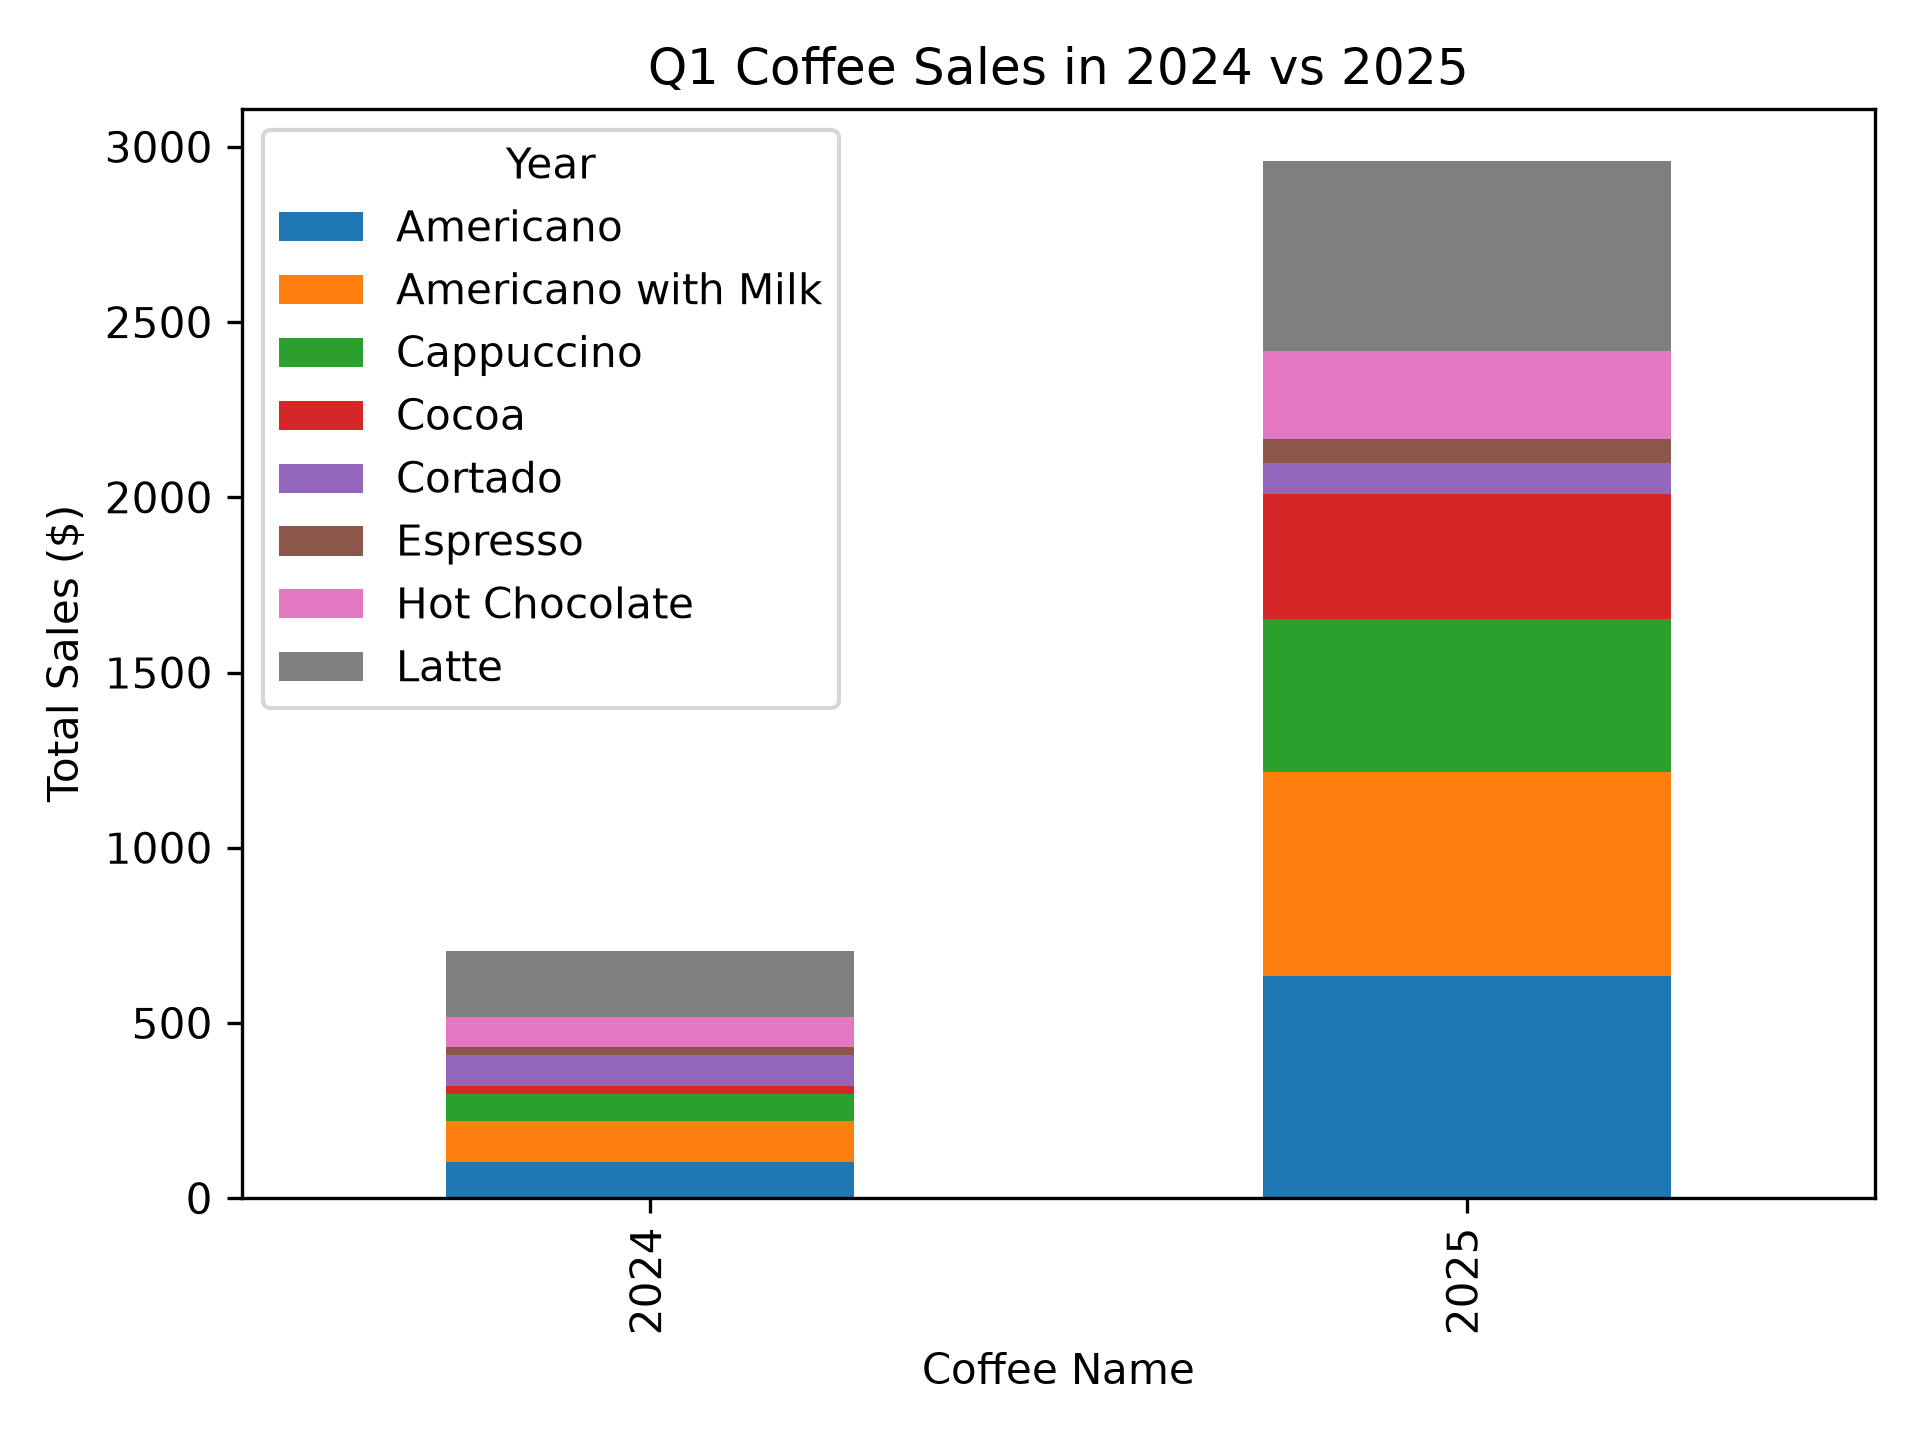


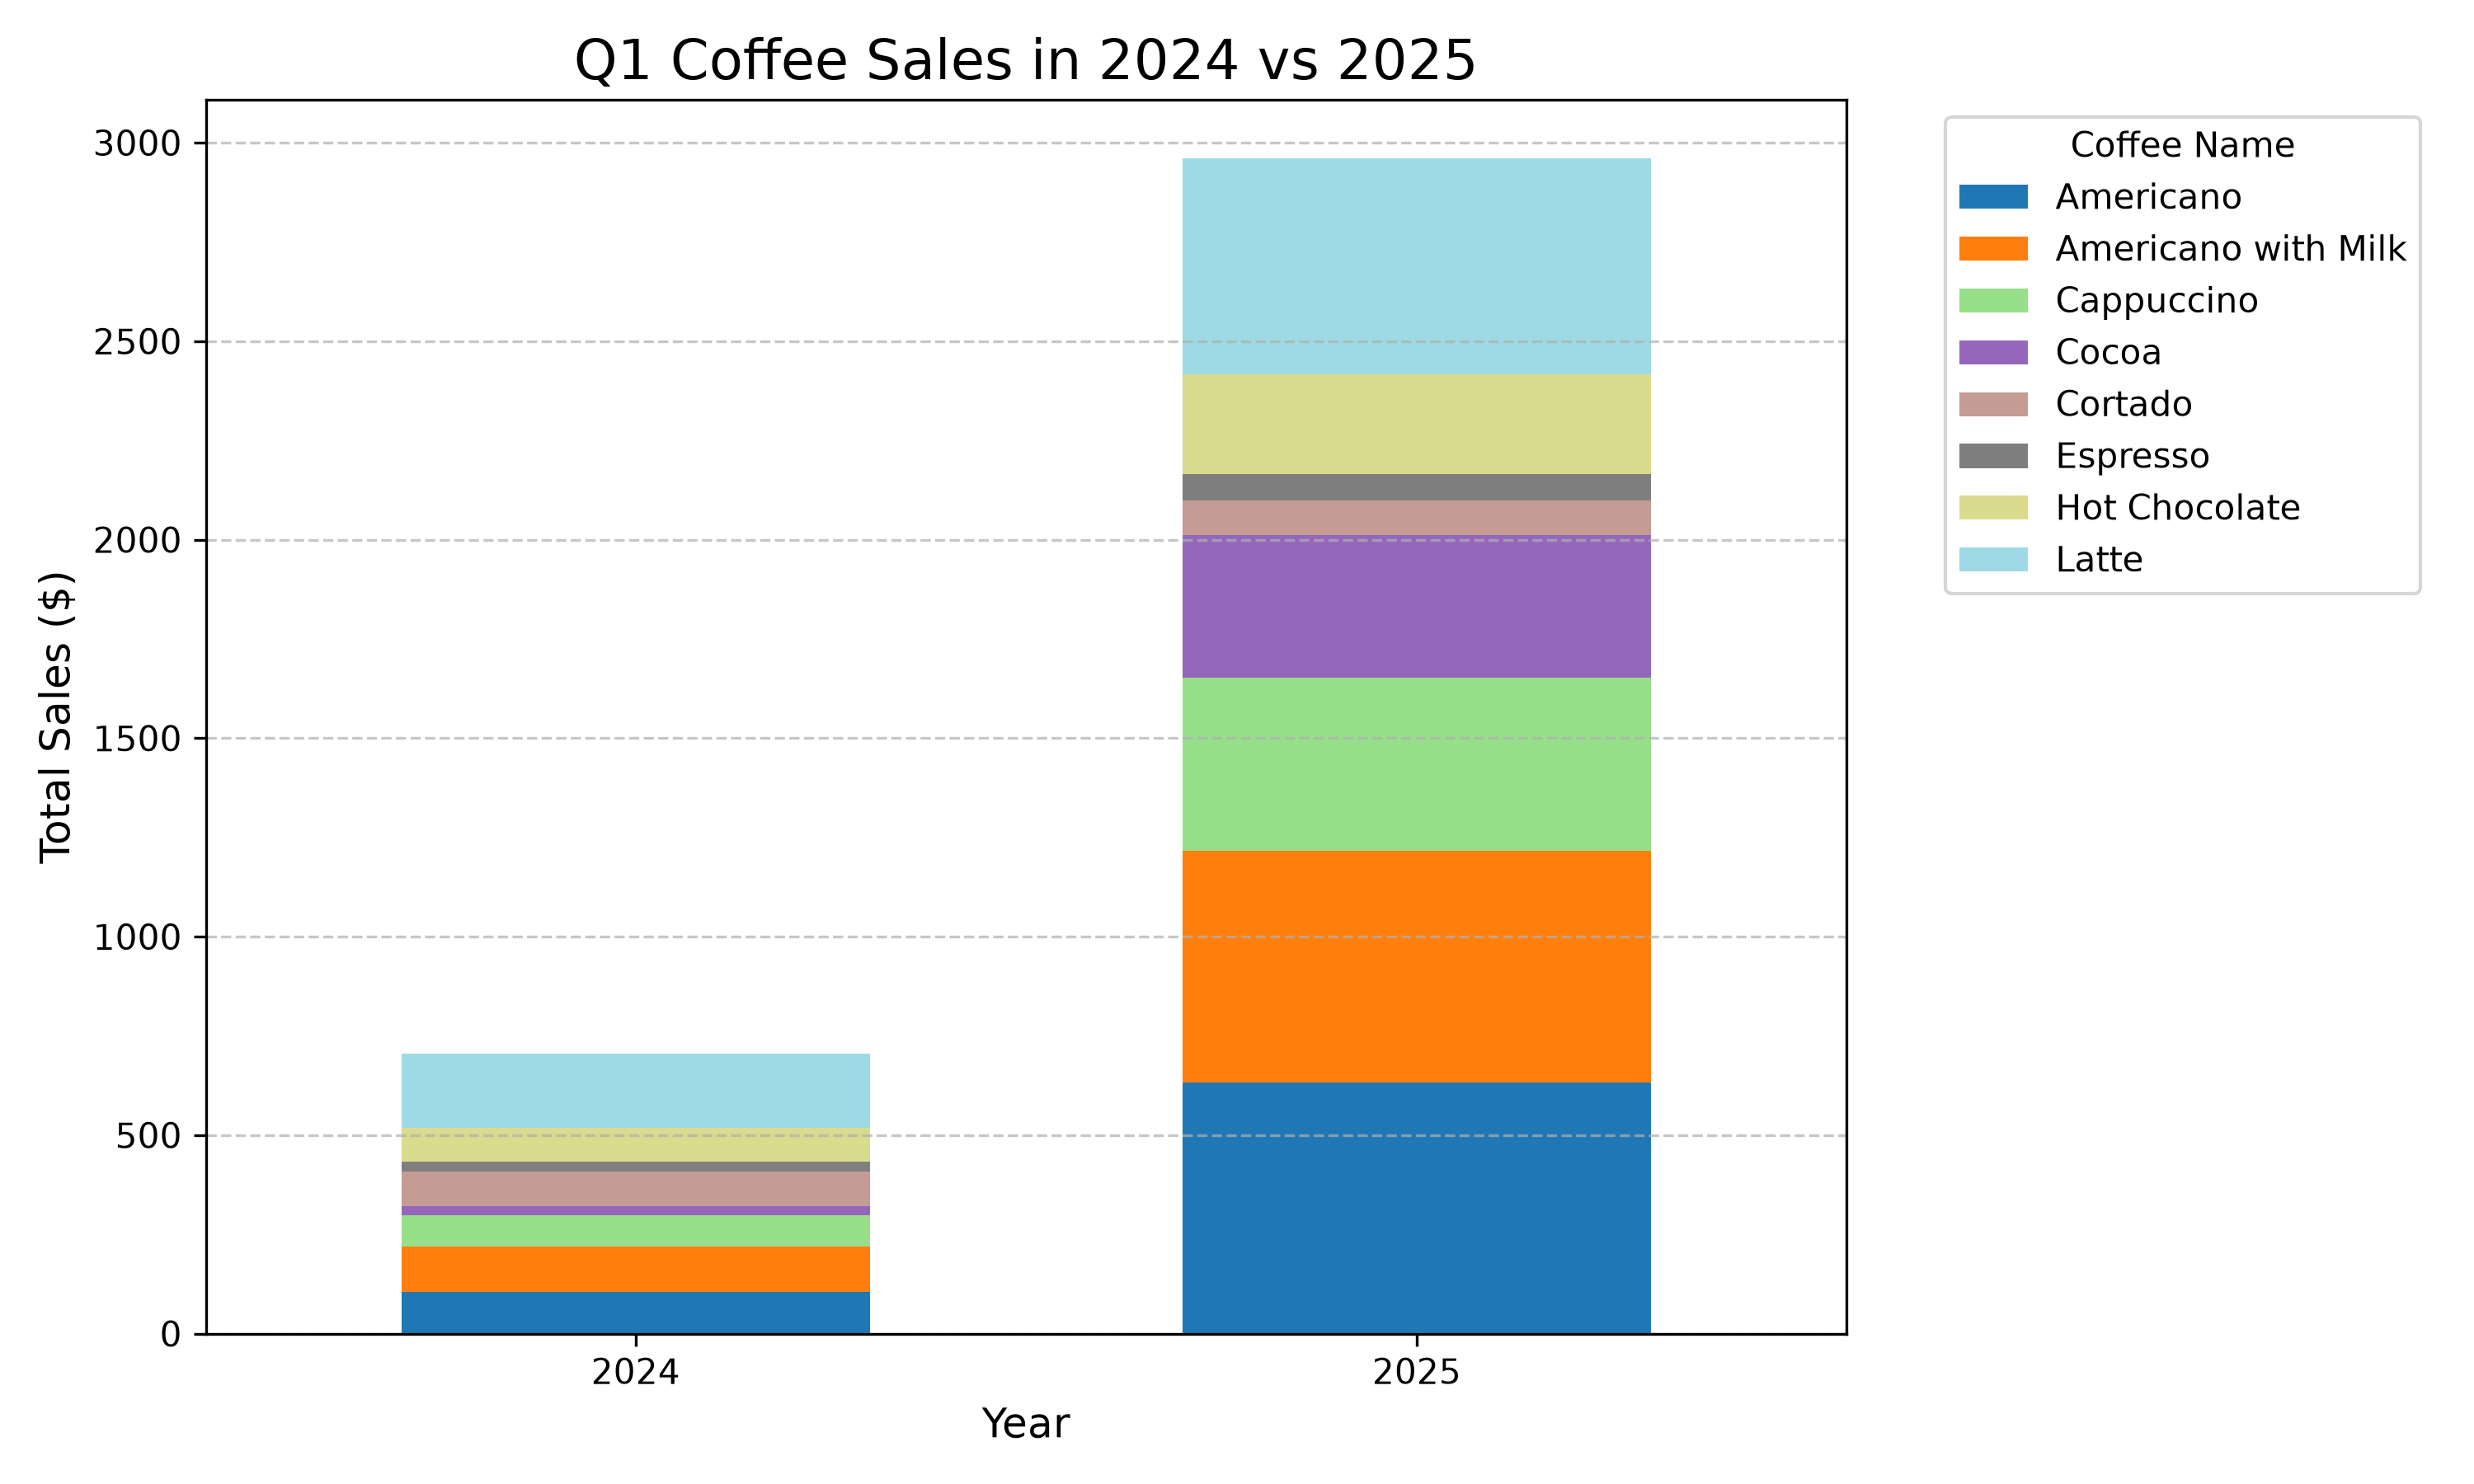

<Figure size 1000x600 with 0 Axes>

In [18]:
# Aquí, introduce tus modificaciones
user_instructions="Create a plot comparing Q1 coffee sales in 2024 and 2025 using the data in coffee_sales.csv." # escribe aquí tu instrucción
generation_model="gpt-4o-mini"
reflection_model="o4-mini"
# reflection_model="gpt-4.1"   # modelo de reflexión alternativo
image_basename="drink_sales"

# Ejecutar el flujo de trabajo agéntico completo
_ = run_workflow(
    dataset_path="coffee_sales.csv",
    user_instructions=user_instructions,
    generation_model=generation_model,
    reflection_model=reflection_model,
    image_basename=image_basename
)

## 5. Conclusiones finales

En este laboratorio, **tú** has practicado el uso de la reflexión para mejorar los resultados de los gráficos.
Has aprendido a:

* Generar un gráfico inicial (V1).
* Criticarlo y refinarlo hasta obtener una versión mejor (V2).
* Automatizar todo el flujo de trabajo utilizando distintos modelos.

La idea clave: la reflexión te ayuda a crear visualizaciones más claras, precisas y eficaces.

<div style="border:1px solid #22c55e; border-left:6px solid #16a34a; background:#dcfce7; border-radius:6px; padding:14px 16px; color:#064e3b; font-family:system-ui,-apple-system,Segoe UI,Roboto,Ubuntu,Cantarell,Noto Sans,sans-serif;">

🎉 <strong>¡Enhorabuena!</strong>

Has completado el laboratorio sobre la construcción de un **flujo de trabajo agéntico para la generación de gráficos**.
A lo largo del laboratorio, **tú** has practicado la generación de gráficos, la reflexión sobre su calidad y su refinamiento para obtener visualizaciones más claras y eficaces.

Con estas habilidades, **tú** estás preparado para diseñar pipelines agénticos que creen visualizaciones de datos automáticamente, manteniéndolas precisas, explicables y bien elaboradas. 🌟

</div>